# Clustering WPT packets using fuzzy c-means

In [1]:
import sys

if sys.version_info[0] + 0.1 * sys.version_info[1] < 3.6:
    raise Exception("Must be using Python 3.6+ version")

In [2]:
%matplotlib inline
sys.path.append("..")
from wavelet_transform.wpt import transform as wpt
from wavelet_transform.test import synthetic_data as sd
from wavelet_transform.wpt import inverse_transform as inv
from wavelet_transform.postprocess import plotting as plot
import wavelet_transform.utils.statistical_features as stats
from wavelet_transform.utils.bubbledynamics import BubbleDynamics as BD

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

In [3]:
pac = -5E5                     # the amplitude of the sine wave in Pa
frequency = 5*1E5             # insonation frequency (Hz)
no_cycle = 20                   # no. of cycles of the sine wave
sampling_rate = frequency*20              # sampling rate to generate the time vector
tstep = 1./sampling_rate
tmax = no_cycle/frequency 
time = np.arange(0.,tmax,tstep) # time vector for computing the sine wave, in seconds
t_plot = time

R_init = 10E-6                  # initial bubble radius in meters
Rdot_init = 0                   # initial bubble's wall velocity in m/s

r_measure = 50*R_init           # distance from the centre of bubble which radiated pressure (acoustic emission from bubble) is calculated over time 

std_noise = 0.01

wavelet = "db20"
levels = 3
mode = "symmetric"

fft_lim = 10*frequency  # increase value to view more of the fft plots

### Generating acoustic emission data using Gilmore-Akulichev model

In [4]:
# generate sound wave

BD_obj = BD(R_init, Rdot_init, frequency, pac, time, tstep)
BD_obj.solver()
BD_obj.calculate_p_radiated(r_measure=r_measure)

data = BD_obj.p_radiated
time = BD_obj.time

signal_length = len(data)

# data += sd.noise(std_noise, duration=time[-1]+tstep, sampling_rate=sampling_rate)

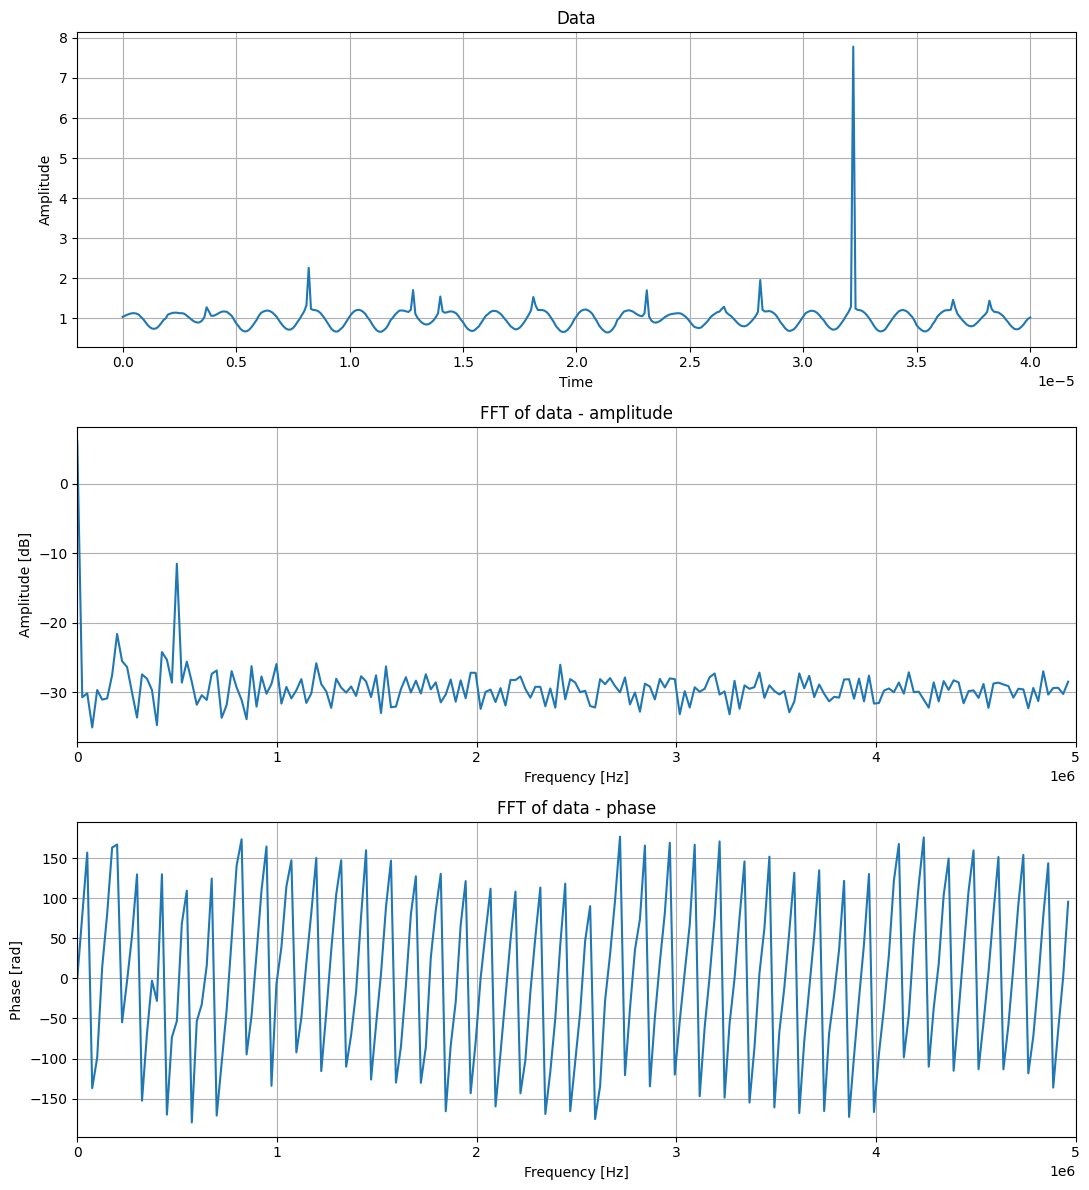

In [5]:
fft_data = np.fft.fft(data)[0 : int(signal_length / 2)] / (
    signal_length / 2
)  # division by signal_length/2 is to correct the amplitude (energy) in the freq domain
freq = np.fft.fftfreq(signal_length, d=1 / sampling_rate)[0 : int(signal_length / 2)]

# plot sound wave and fft
fig, ax = plt.subplots(3, figsize=(11, 12))
ax[0].plot(t_plot, data)
ax[0].set_title("Data")
ax[0].set_xlabel("Time")
ax[0].set_ylabel("Amplitude")
ax[0].grid()

ax[1].plot(
    freq,
    20*np.log10(np.abs(fft_data))
)
ax[1].set_title("FFT of data - amplitude")
ax[1].set_xlabel("Frequency [Hz]")
ax[1].set_ylabel("Amplitude [dB]")
ax[1].set_xlim(0, fft_lim)
ax[1].grid()

ax[2].plot(freq, np.angle(fft_data, deg=True))
ax[2].set_title("FFT of data - phase")
ax[2].set_xlabel("Frequency [Hz]")
ax[2].set_ylabel("Phase [rad]")
ax[2].set_xlim(0, fft_lim)
ax[2].grid()
fig.tight_layout()
plt.show()

### synthetic data
override the original data with synthetic data

In [6]:
use_synthetic_data = False  # set to False to use dynamic model instead

In [7]:
if use_synthetic_data is True:
    # keep the same
    sampling_rate = 100  # unit: Hz

    # PARAMETERS TO CHANGE
    amplitudes = [1, 1]  # amplitude of each sine wave
    frequencies = [5, 15]  # frequency content of signal
    phases = [0, np.deg2rad(45)]  # phase of each sine wave

    duration = 300 / min(frequencies)  # duration of wave

    trans_amp = [1 for _ in range(5)]  # amplitudes of transients
    n_trans = len(trans_amp)  # number of transients
    trans_dur = [0.05 for _ in range(n_trans)]  # duration of transients
    trans_time = [
        duration * i / (n_trans + 1) for i in range(1, n_trans + 1)
    ]  # times of transients

    std_noise = 0.1

    wavelet = "db20"
    levels = 8
    mode = "symmetric"

    fft_lim = 50  # increase value to view more of the fft plots

In [8]:
def generate_synth_data():   
    # generate sound wave
    data, t_plot = sd.sound_wave(amplitudes, frequencies, phases, duration, sampling_rate)
    signal_length = len(data)
    transient_signal = sd.transients(
        trans_amp, trans_time, trans_dur, duration, sampling_rate
    )
    data += transient_signal
    # data += sd.noise(std_noise, duration, sampling_rate)
    data *= np.hamming(signal_length)

    fft_data = np.fft.fft(data)[0 : int(signal_length / 2)] / (
        signal_length / 2
    )  # division by signal_length/2 is to correct the amplitude (energy) in the freq domain
    freq = np.fft.fftfreq(signal_length, d=1 / sampling_rate)[0 : int(signal_length / 2)]

    # plot sound wave and fft
    fig, ax = plt.subplots(3, figsize=(11, 12))
    ax[0].plot(t_plot, data)
    ax[0].set_title("Data")
    ax[0].set_xlabel("Time")
    ax[0].set_ylabel("Amplitude")
    ax[0].grid()

    ax[1].stem(
        freq,
        np.abs(fft_data),
        linefmt="b",
        markerfmt=" ",
        basefmt="-b",
        use_line_collection=True,
    )
    ax[1].set_title("FFT of data - amplitude")
    ax[1].set_xlabel("Frequency [Hz]")
    ax[1].set_ylabel("Amplitude [DL]")
    ax[1].set_xlim(0, sampling_rate / 2)
    ax[1].grid()

    ax[2].plot(freq, np.angle(fft_data, deg=True))
    ax[2].set_title("FFT of data - phase")
    ax[2].set_xlabel("Frequency [Hz]")
    ax[2].set_ylabel("Phase [rad]")
    ax[2].set_xlim(0, sampling_rate / 2)
    ax[2].grid()
    fig.tight_layout()
    plt.show()
    return data

In [9]:
if use_synthetic_data is True:
    synthetic_data = generate_synth_data()
    data = synthetic_data

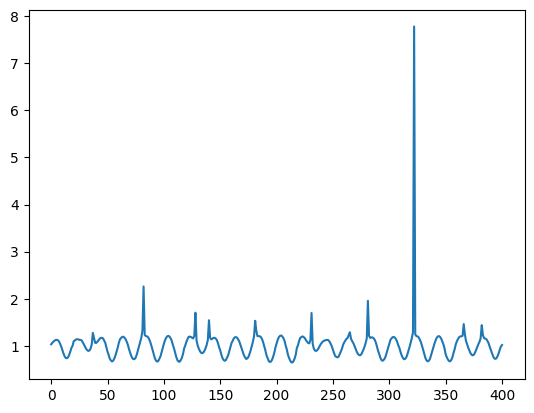

In [10]:
plt.plot(data)
plt.show()

In [11]:
# Set display options
pd.set_option("display.max_rows", None)  # Show all rows
pd.set_option("display.max_columns", None)  # Show all columns


# DWPT
tr_ob = wpt.dwpt(data, levels, wavelet, mode)
tr_ob.calc_frequencies(sampling_rate)

# calculate energy, kurtosis, and crest factor of reconstructed signals
wpt_df = pd.DataFrame(
    columns=[
        "node",
        "inverse",
        "fft",
        "energy",
        "kurtosis",
        "crest",
        "entropy",
        "skewness",
    ]
)

total_energy = stats.energy(data)

# reconstruct each node separately
counter = 0
for node in tr_ob.get_level(level=levels, order="freq"):
    node_data = node.data  # coefficients from transform

    # calculate inverse transform
    inverse = inv.inv_dwpt(tr_ob, nodes=node)
    inverse_signal_length = len(inverse)

    # calculate fft of inverse
    fft = np.fft.fft(inverse)[0 : int(inverse_signal_length / 2)] / (
        inverse_signal_length * 0.5
    )

    # calculate statistical measures
    kurtosis = stats.kurtosis(node_data)
    skewness = stats.skewness(node_data)
    crest = stats.crest_factor(node_data)

    wpt_df.loc[counter, "node"] = node
    wpt_df.loc[counter, "inverse"] = inverse
    wpt_df.loc[counter, "fft"] = fft
    wpt_df.loc[counter, "energy"] = node.energy
    wpt_df.loc[counter, "kurtosis"] = kurtosis
    wpt_df.loc[counter, "crest"] = crest
    wpt_df.loc[counter, "entropy"] = node.entropy
    wpt_df.loc[counter, "skewness"] = skewness
    counter += 1

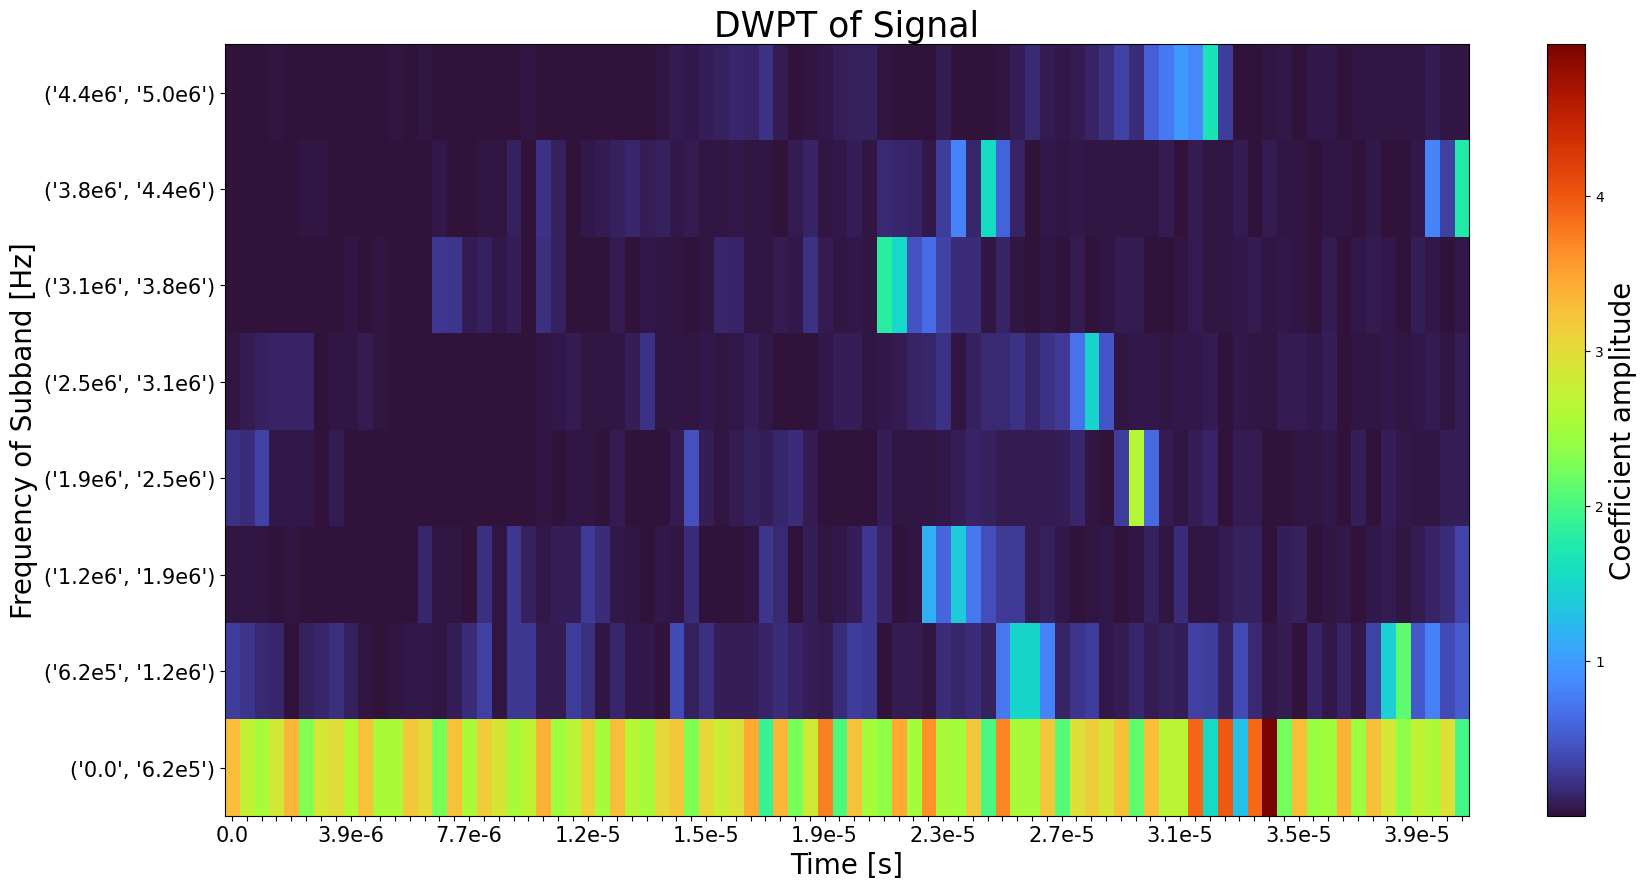

In [12]:
plot.heisenberg(tr_ob, max(t_plot))

## Fuzzy c-means clustering

In [13]:
from sklearn.preprocessing import StandardScaler
import skfuzzy as fuzz

# get data
classifying_metrics = ["energy", "kurtosis", "crest", "entropy"]
data_train = wpt_df[classifying_metrics]

# standardise data
scaler = StandardScaler()
data_train_normalised = scaler.fit_transform(data_train)

# parameters for Fuzzy C-means
no_clusters = 3
m = 2.0
error = 1e-6

# Fuzzy C-Means clustering
cntr, u, u0, d, jm, p, fpc = fuzz.cluster.cmeans(
    data_train_normalised.T,
    c=no_clusters,
    m=m,
    error=error,
    maxiter=100,
)
print("number of iterations:", p)
# cluster centres
print("centres", cntr)
centers = scaler.inverse_transform(cntr)

# membership matrix
membership_matrix = u.T

# hard cluster assignments
labels = np.argmax(membership_matrix, axis=1)
for i in range(no_clusters):
    print(f"label {i} count:", list(labels).count(i))

membership_results = pd.DataFrame()
for i, membership in enumerate(membership_matrix):
    membership_results.loc[i, "hard assignment"] = labels[i]
    for j in range(no_clusters):
        membership_results.loc[i, f"membership {j}"] = membership[j]

membership_results.head()

number of iterations: 17
centres [[ 2.30261115 -1.31035484 -2.41873065  2.27901288]
 [-0.28295841  2.10062214  0.97907994 -1.204438  ]
 [-0.40915936 -0.1377252   0.2554331  -0.22034129]]
label 0 count: 1
label 1 count: 1
label 2 count: 6


,hard assignment,membership 0,membership 1,membership 2
0,0.0,0.999375,0.000217,0.000407
1,2.0,0.168012,0.129661,0.702327
2,2.0,0.014053,0.030821,0.955126
3,1.0,0.000465,0.996750,0.002785
4,2.0,0.023295,0.203932,0.772773


In [14]:
from sklearn import metrics
from collections import defaultdict
from time import time
evaluations = []
evaluations_std = []

def fit_and_evaluate(X, labels, n_runs=50):
    name = "fuzzy c-means"

    train_times = []
    scores = defaultdict(list)
    for _ in range(n_runs):
        t0 = time()

        _, u, *_ = fuzz.cluster.cmeans(X, c=no_clusters, m=m, error=error, maxiter=150)
        membership_matrix = u.T
        new_labels = np.argmax(membership_matrix, axis=1)

        train_times.append(time() - t0)
        scores["Homogeneity"].append(metrics.homogeneity_score(labels, new_labels))
        scores["Completeness"].append(metrics.completeness_score(labels, new_labels))
        scores["V-measure"].append(metrics.v_measure_score(labels, new_labels))
        scores["Adjusted Rand-Index"].append(
            metrics.adjusted_rand_score(labels, new_labels)
        )
        scores["Silhouette Coefficient"].append(
            metrics.silhouette_score(X.T, new_labels, sample_size=2000)
        )
    train_times = np.asarray(train_times)

    print(f"clustering done in {train_times.mean():.2f} ± {train_times.std():.2f} s ")
    evaluation = {
        "estimator": name,
        "train_time": train_times.mean(),
    }
    evaluation_std = {
        "estimator": name,
        "train_time": train_times.std(),
    }
    for score_name, score_values in scores.items():
        mean_score, std_score = np.mean(score_values), np.std(score_values)
        print(f"{score_name}: {mean_score:.3f} ± {std_score:.3f}")
        evaluation[score_name] = mean_score
        evaluation_std[score_name] = std_score
    evaluations.append(evaluation)
    evaluations_std.append(evaluation_std)

In [15]:
fit_and_evaluate(data_train_normalised.T, labels)

clustering done in 0.00 ± 0.00 s 
Homogeneity: 1.000 ± 0.000
Completeness: 1.000 ± 0.000
V-measure: 1.000 ± 0.000
Adjusted Rand-Index: 1.000 ± 0.000
Silhouette Coefficient: 0.436 ± 0.000


Post hoc assignment of cluster labels. Highest cluster number is the lowest entropy cluster, the rest is sorted by kurtosis or crest factor.

In [16]:
def map_labels_entropy(centers, sort_by=1):
    """
    assign labels to clusters. Assign the highest cluster number to the centre with
    lowest entropy. Then assign the rest in order of sort_by. The group numbers are reassigned
    to 1-indexed groups.

    Paramaters
    -----------
    centers: array
        array where each row is a centre of a cluster
    labels: list
        list of group assignments to reassign
    sort_by: int
        always sort out the highest energy because the harmonic can be separated
        from the rest by its much greater energy. Otherwise, sort by attribute
        number = sort_by of the centres. e.g. sort_by == 1 will sort the rest
        by kurtosis, sort_by == 2 will sort by crest factor etc.
    """
    # sort labels by entropy, lowest entropy is highest group number
    sort_by_entropy = np.argsort(centers[:, 0])[::-1]  # assumes entropy is in 1st position

    # sort rest of the labels by kurtosis
    sort_rest = np.argsort(centers[:, sort_by])

    sort_rest = np.delete(
        sort_rest,  # delete lowest entropy group form kurtosis
        np.where(sort_rest == sort_by_entropy[-1])[0][0],
        axis=0,
    )
    sort_rest = np.append(sort_rest, None)

    # create mapping from old cluster labels to new cluster labels
    mapping = {}
    for new_label, index in enumerate(zip(sort_by_entropy, sort_rest)):
        if new_label == len(sort_by_entropy) - 1:  # highest group no has highest energy
            mapping[index[0]] = new_label + 1
        else:
            mapping[index[1]] = (
                new_label + 1
            )  # other group numbers are arranged by kurtosis

    return mapping

In [17]:
mapping = map_labels_entropy(centers)
print(mapping)

{0: 1, 1: 2, 2: 3}


In [18]:
# reassigning labels
reassigned_labels = [mapping[label] for label in labels]
print(reassigned_labels)
for i in range(1, no_clusters + 1):
    print(f"label {i} count:", list(reassigned_labels).count(i))

[1, 3, 3, 2, 3, 3, 3, 3]
label 1 count: 1
label 2 count: 1
label 3 count: 6


### Calculating soft assignment

Reassign labels by taking summing the cluster numbers each data point belongs to, weigted by their membership to the cluster. Result is a membership number [1, n]. Where n is the number of clusters. [n-1, n] indicates mixture between harmonic (n) and transient (n - 1). values between [1, n-1] are more transient when approaching n-1. The hard assignment can be found as reassigned_labels above.

In [19]:
soft_assignments = [
    sum([mapping[i] * weight for i, weight in enumerate(membership)])
    for membership in membership_matrix
]
print(soft_assignments)

[1.0010323566628943, 2.534314451740874, 2.9410720384462308, 2.0023201795225916, 2.749478449129778, 2.9329844400560434, 2.9916515574259486, 2.990273870470776]


Plot results

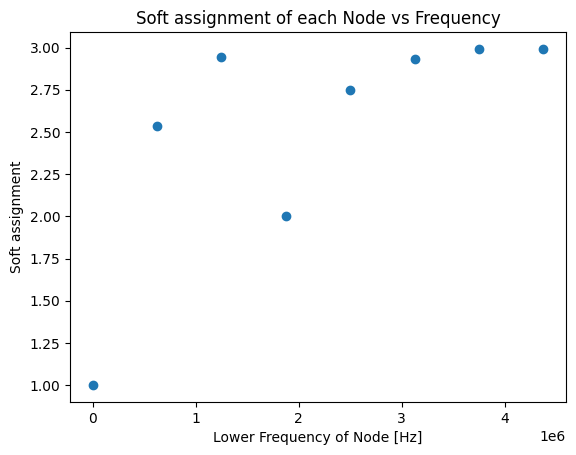

In [20]:
# plot weighted reassigned labels
plt.scatter([node.frequency_range[0] for node in wpt_df["node"]], soft_assignments)
plt.title("Soft assignment of each Node vs Frequency")
plt.xlabel("Lower Frequency of Node [Hz]")
plt.ylabel("Soft assignment")
plt.show()

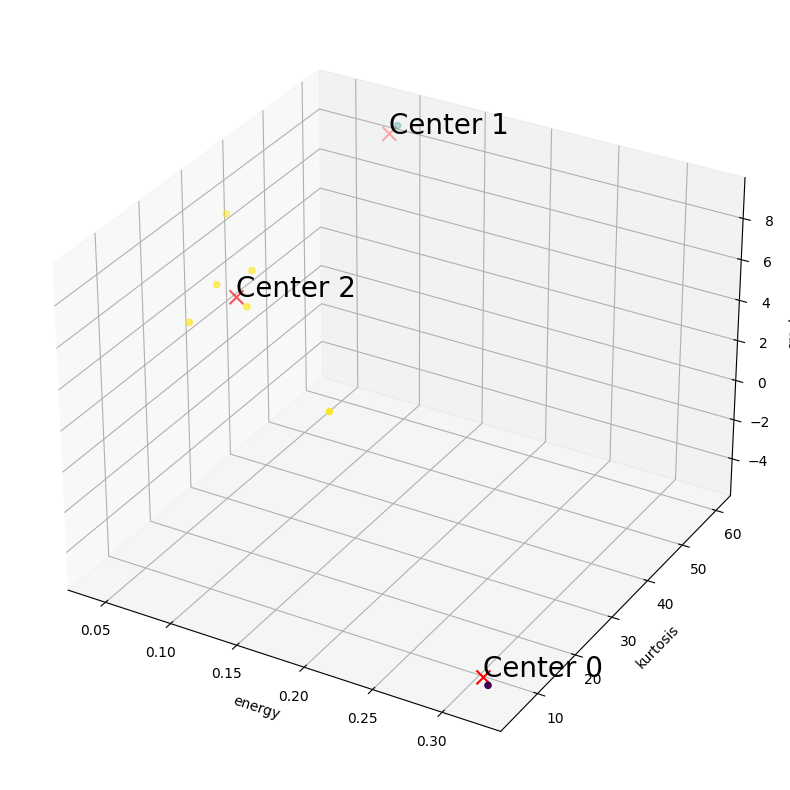

In [21]:
import matplotlib.pyplot as plt

fig = plt.figure(figsize=(10, 10))
ax = fig.add_subplot(111, projection="3d")

data_scatter = data_train.values.tolist()
centers_scatter = centers
labels_scatter = reassigned_labels
color_map_labels = reassigned_labels

# Plot data points
data_plot = ax.scatter(
    [point[0] for point in data_scatter],
    [point[1] for point in data_scatter],
    [point[2] for point in data_scatter],
    c=color_map_labels
)

# Plot cluster centers after data points
center_plot = ax.scatter(
    centers_scatter[:, 0],
    centers_scatter[:, 1],
    centers_scatter[:, 2],
    c="red",
    marker="x",
    s=100,
)

ax.set_xlabel(data_train.columns[0])
ax.set_ylabel(data_train.columns[1])
ax.set_zlabel(data_train.columns[2])

# Annotate cluster centers with their positions
for i, center in enumerate(centers_scatter):
    ax.text(center[0], center[1], center[2], f'Center {i}', color='black', fontsize=20)

plt.show()

Reconstructed nodes by group:


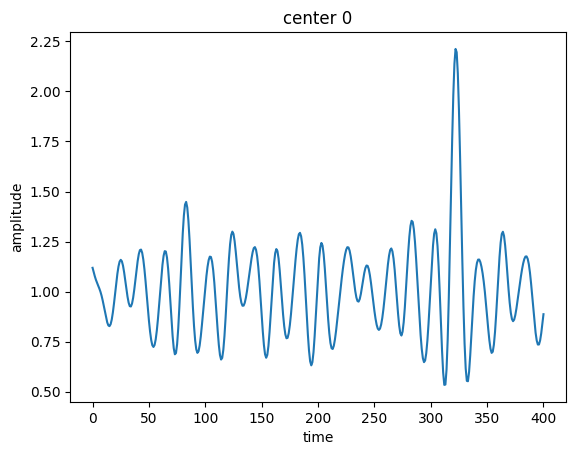

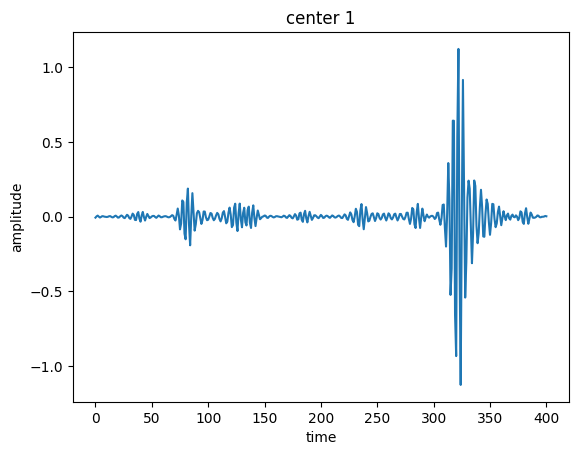

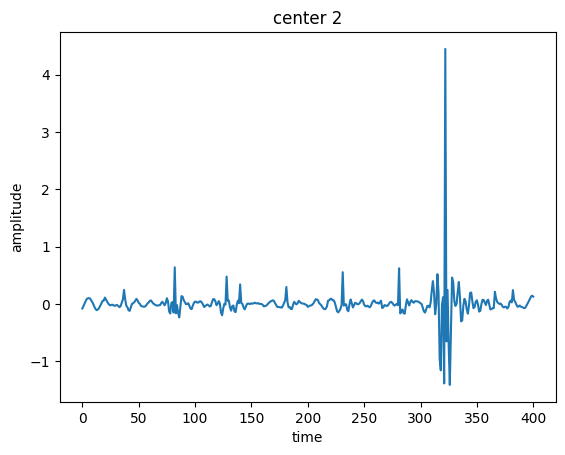

In [22]:
plot.plot_reconstructions_by_group(tr_ob, labels, no_clusters, order="freq")